# Telecom Customer Churn Analysis
**Tools:** Python, Pandas, Matplotlib, Seaborn, Scikit-learn, imbalanced-learn  
**Dataset:** public IBM Telco dataset (7,043 rows; 7,032 after dropping 11 blank TotalCharges). 1M-subscriber figures are a scenario.

## Key Findings
1. **26.6%** overall churn rate: 1 in 4 customers leaving
2. **Month-to-month** customers churn at **42.7%**: 15x higher than two-year contracts
3. **Fiber optic** customers churn at **41.9%** despite paying premium prices
4. Churners pay **$13.13 more/month** on average than retained customers
5. **First 6 months** are the highest-risk window: 53% churn rate for tenure ≤ 6 months; 42% of churners leave within 6 months; median churner tenure is 10 months.
6. Logistic Regression: **ROC-AUC 0.836** and **80% accuracy** on a held-out test set (5-fold CV AUC 0.846).

## Business Recommendations
1. Convert month-to-month customers to annual contracts via incentives
2. Investigate fiber optic service quality and pricing
3. Launch early onboarding program for customers in months 1–6
4. Target high monthly charge customers with loyalty discounts

In [102]:
!pip install kagglehub

In [103]:
import os
# Set your Kaggle API token via kagglehub.login() before running

import kagglehub
path = kagglehub.dataset_download("blastchar/telco-customer-churn")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn


In [104]:
import pandas as pd

df = pd.read_csv(path + '/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [105]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [106]:
print("Dataset shape:", df.shape)
print("\nChurn distribution:")
print(df['Churn'].value_counts())
print("\nChurn percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

Dataset shape: (7043, 21)

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [107]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [108]:
# Check for duplicates
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [109]:
# Fix TotalCharges — convert to numeric, spaces become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check how many rows got NaN
print("NaN in TotalCharges after conversion:", df['TotalCharges'].isnull().sum())

# Drop those rows (will be very few)
df = df.dropna(subset=['TotalCharges'])

# Confirm fix
print("TotalCharges dtype now:", df['TotalCharges'].dtype)
print("Dataset shape after cleaning:", df.shape)

NaN in TotalCharges after conversion: 11
TotalCharges dtype now: float64
Dataset shape after cleaning: (7032, 21)


In [110]:
df = df.drop(columns=['customerID'])
print("Final shape:", df.shape)

Final shape: (7032, 20)


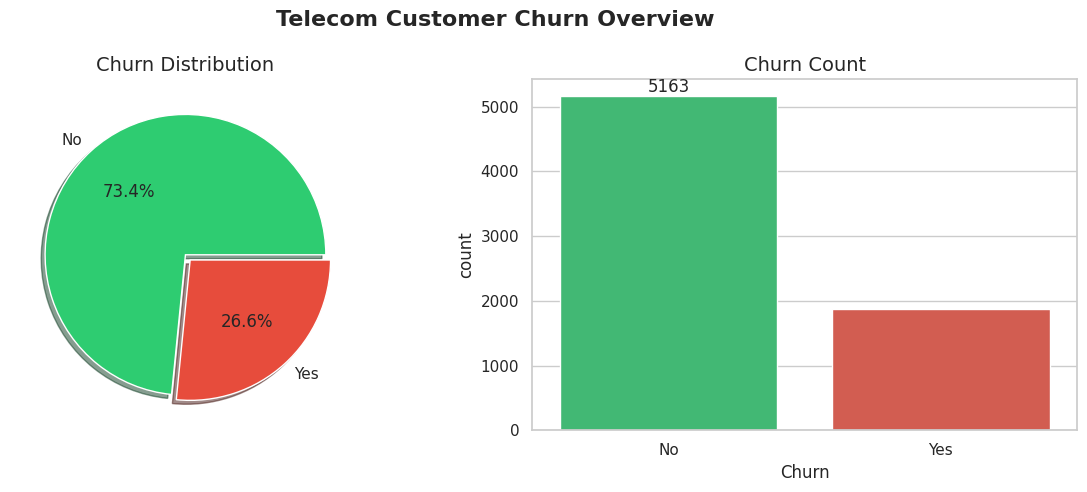

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style='whitegrid')

# Churn distribution pie chart
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pie chart
df['Churn'].value_counts().plot.pie(
    ax=axes[0],
    autopct='%1.1f%%',
    colors=['#2ecc71', '#e74c3c'],
    explode=[0, 0.05],
    shadow=True
)
axes[0].set_title('Churn Distribution', fontsize=14)
axes[0].set_ylabel('')

# Count bar chart
sns.countplot(data=df, x='Churn',hue='Churn', ax=axes[1], palette=['#2ecc71', '#e74c3c'], legend=False)
axes[1].set_title('Churn Count', fontsize=14)
axes[1].bar_label(axes[1].containers[0])

plt.suptitle('Telecom Customer Churn Overview', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## Churn Overview

**Key Finding:** 26.6% of customers churned, roughly 1 in 4 customers.

A 1-in-4 churn rate is a significant revenue leak for any subscription business.


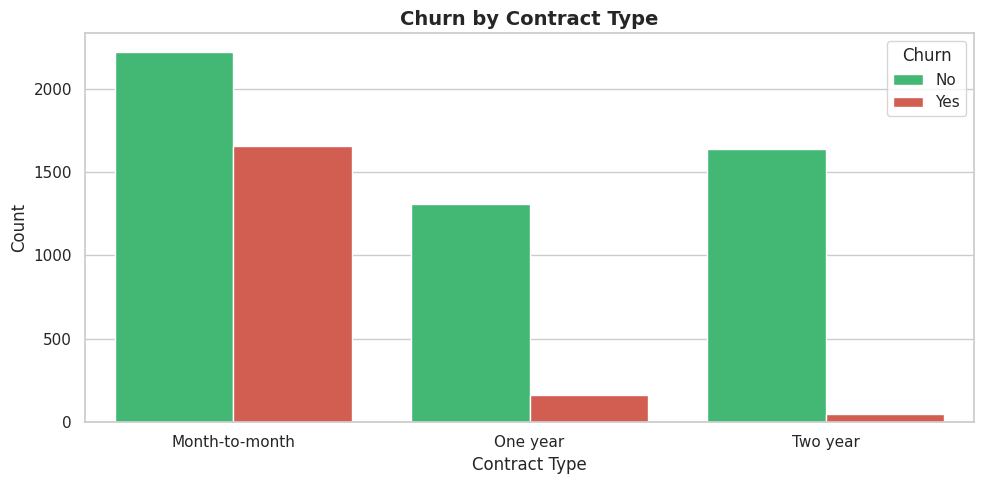

In [112]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Contract', hue='Churn', palette=['#2ecc71', '#e74c3c'])
plt.title('Churn by Contract Type', fontsize=14, fontweight='bold')
plt.xlabel('Contract Type')
plt.ylabel('Count')
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

In [113]:
churn_by_contract = df.groupby('Contract')['Churn'].value_counts(normalize=True).mul(100).round(1)
print(churn_by_contract)

Contract        Churn
Month-to-month  No       57.3
                Yes      42.7
One year        No       88.7
                Yes      11.3
Two year        No       97.2
                Yes       2.8
Name: proportion, dtype: float64


## Churn by Contract Type

**Key Finding:** Contract type shows the widest churn gap (42.7% vs 2.8%, about 15x).

| Contract Type  | Retained | Churned |
|----------------|----------|---------|
| Month-to-month | 57.3%    | 42.7%   |
| One year       | 88.7%    | 11.3%   |
| Two year       | 97.2%    | 2.8%    |

Month-to-month customers churn at **42.7%**: nearly 15x higher than two-year
contract customers (2.8%).

**Business Recommendation:** Month-to-month is the largest at-risk group. Test incentives for longer contracts; this data can’t show that contract type causes retention.

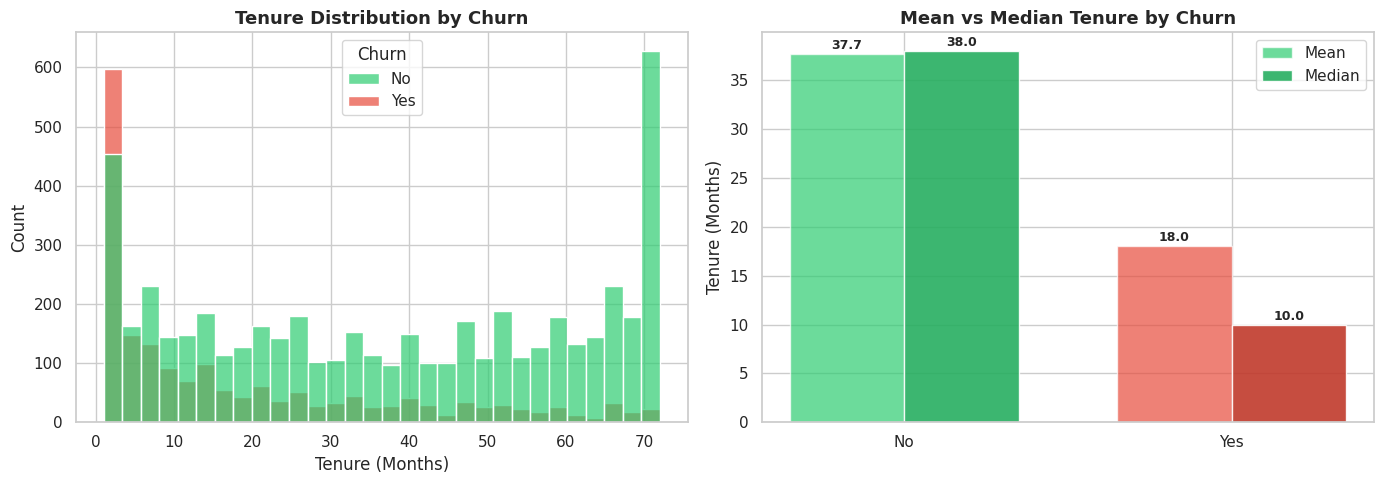

In [114]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tenure distribution by churn
sns.histplot(data=df, x='tenure', hue='Churn',
             palette=['#2ecc71', '#e74c3c'],
             bins=30, ax=axes[0], alpha=0.7)
axes[0].set_title('Tenure Distribution by Churn', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Tenure (Months)')

# Mean vs Median tenure by churn
tenure_stats = df.groupby('Churn')['tenure'].agg(['mean', 'median']).round(1)

x = range(len(tenure_stats))
width = 0.35

bars1 = axes[1].bar([i - width/2 for i in x], tenure_stats['mean'],
                     width, color=['#2ecc71', '#e74c3c'], alpha=0.7, label='Mean')
bars2 = axes[1].bar([i + width/2 for i in x], tenure_stats['median'],
                     width, color=['#27ae60', '#c0392b'], alpha=0.9, label='Median')

axes[1].set_title('Mean vs Median Tenure by Churn', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Tenure (Months)')
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(tenure_stats.index)
axes[1].legend()

# Add value labels on bars
for bar in bars1:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 str(round(bar.get_height(), 1)), ha='center', fontweight='bold', fontsize=9)
for bar in bars2:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 str(round(bar.get_height(), 1)), ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

## Tenure vs Churn

**Key Finding:** Churn is heavily concentrated in the first few months,
and the median tells a more alarming story than the mean.

| Metric | Retained (No) | Churned (Yes) |
|--------|--------------|---------------|
| Mean Tenure | 37.7 months | 18.0 months |
| Median Tenure | 38.0 months | 10.0 months |

- The **median churned customer leaves after just 10 months**,
  the mean of 18 months was hiding how early most churners actually leave
- Bimodal: many new customers and many long-tenured ones
- Churned customers show a large gap between mean (18) and median (10),
  confirming the distribution is right-skewed, pulled up by a minority of
  churners who stayed longer before leaving
- The histogram confirms a massive churn spike in months 1–2,
  with churn falling from 53% in months 0-6 to 36% in months 7-12

**Why median matters here:** Using mean alone (18 months) understates the
urgency, the typical churner is actually gone by month 10, not month 18.

**Business Recommendation:** The critical intervention window is the
**first 6 months**, not the first 18. Telcos should invest in:
- Proactive onboarding support in months 1–3
- A loyalty check-in offer at month 6
- Early warning flags for month-to-month customers approaching month 10
- Churn rate falls steadily with tenure: 53.3% (0-6 months), 35.9% (7-12), 28.7% (13-24), 20.4% (25-48), 9.5% (49-72). 41.9% of churners leave within 6 months and 55.5% within 12, which is why onboarding in the first 6 months is the focus.

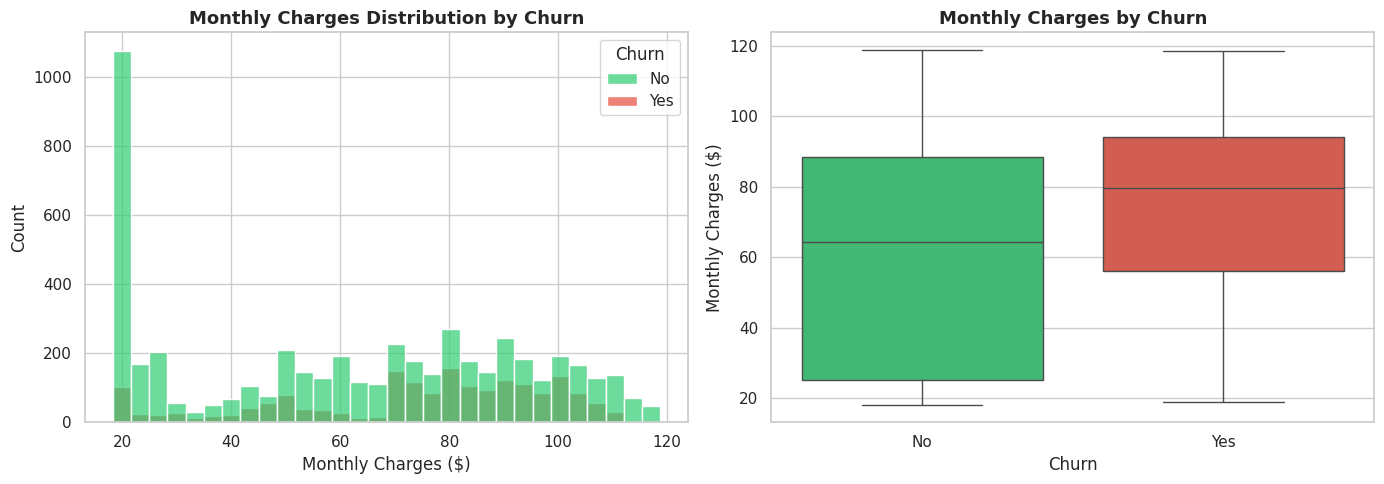

Churn
No     61.31
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [115]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution
sns.histplot(data=df, x='MonthlyCharges', hue='Churn',
             palette=['#2ecc71', '#e74c3c'],
             bins=30, ax=axes[0], alpha=0.7)
axes[0].set_title('Monthly Charges Distribution by Churn', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Monthly Charges ($)')

# Box plot
sns.boxplot(data=df, x='Churn', hue='Churn', y='MonthlyCharges',palette=['#2ecc71', '#e74c3c'], ax=axes[1], legend=False)
axes[1].set_title('Monthly Charges by Churn', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Churn')
axes[1].set_ylabel('Monthly Charges ($)')

plt.tight_layout()
plt.show()

# Print averages
print(df.groupby('Churn')['MonthlyCharges'].mean().round(2))

## Monthly Charges vs Churn

**Key Finding:** Customers who churn pay significantly more than those who stay.

- Average monthly charge for churned customers: **$74.44**

- Average monthly charge for retained customers: **$61.31**

- A **$13.13 difference (21% higher)** for customers who leave

This suggests churned customers may feel they are not getting value for money. High-paying customers on month-to-month contracts are likely the highest risk segment, paying premium prices with no long-term commitment.

**Business Recommendation:** Introduce value-added services or loyalty discounts for high-paying month-to-month customers. Whether a targeted offer pays for itself needs offer-cost and acquisition-cost data not in this dataset.

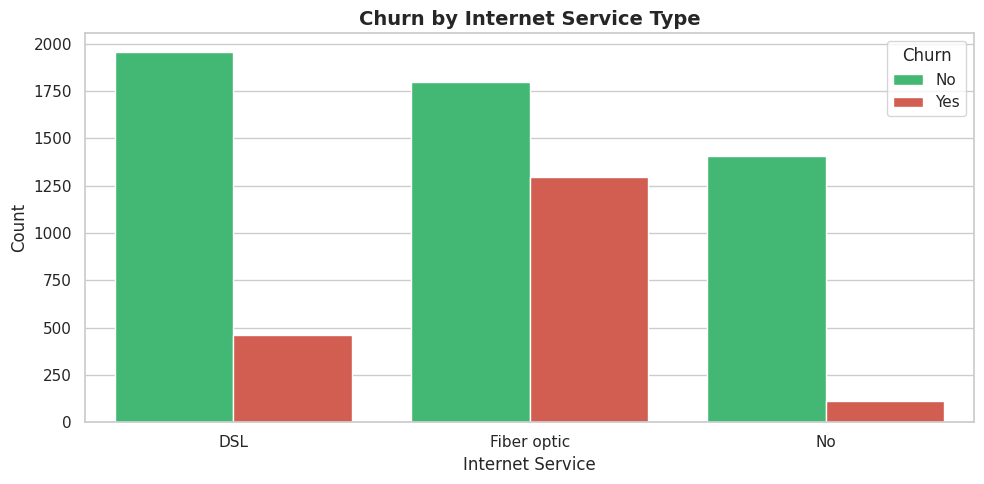

InternetService  Churn
DSL              No       81.0
                 Yes      19.0
Fiber optic      No       58.1
                 Yes      41.9
No               No       92.6
                 Yes       7.4
Name: proportion, dtype: float64
InternetService
DSL            58.09
Fiber optic    91.50
No             21.08
Name: MonthlyCharges, dtype: float64


In [116]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='InternetService', hue='Churn',
              palette=['#2ecc71', '#e74c3c'])
plt.title('Churn by Internet Service Type', fontsize=14, fontweight='bold')
plt.xlabel('Internet Service')
plt.ylabel('Count')
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

print(df.groupby('InternetService')['Churn'].value_counts(normalize=True).mul(100).round(1))
print(df.groupby('InternetService')['MonthlyCharges'].mean()

## Churn by Internet Service Type

**Key Finding:** Fiber optic customers churn at 41.9% - more than double the DSL rate.

| Internet Service | Churn Rate |
|-----------------|------------|
| No internet     | 7.4%       |
| DSL             | 19.0%      |
| Fiber optic     | 41.9%      |

Fiber optic is the highest-priced service ($91.50/month on average vs $58.09 for DSL) and has the highest churn. This is consistent with a possible value-for-money problem, but this data cannot separate service quality from price. It also explains much of why churners pay more on average.

**Business Recommendation:** Urgently investigate fiber optic service quality,
pricing competitiveness, and customer satisfaction. Consider introducing a
fiber optic loyalty tier with added benefits to reduce churn in this high-value segment.

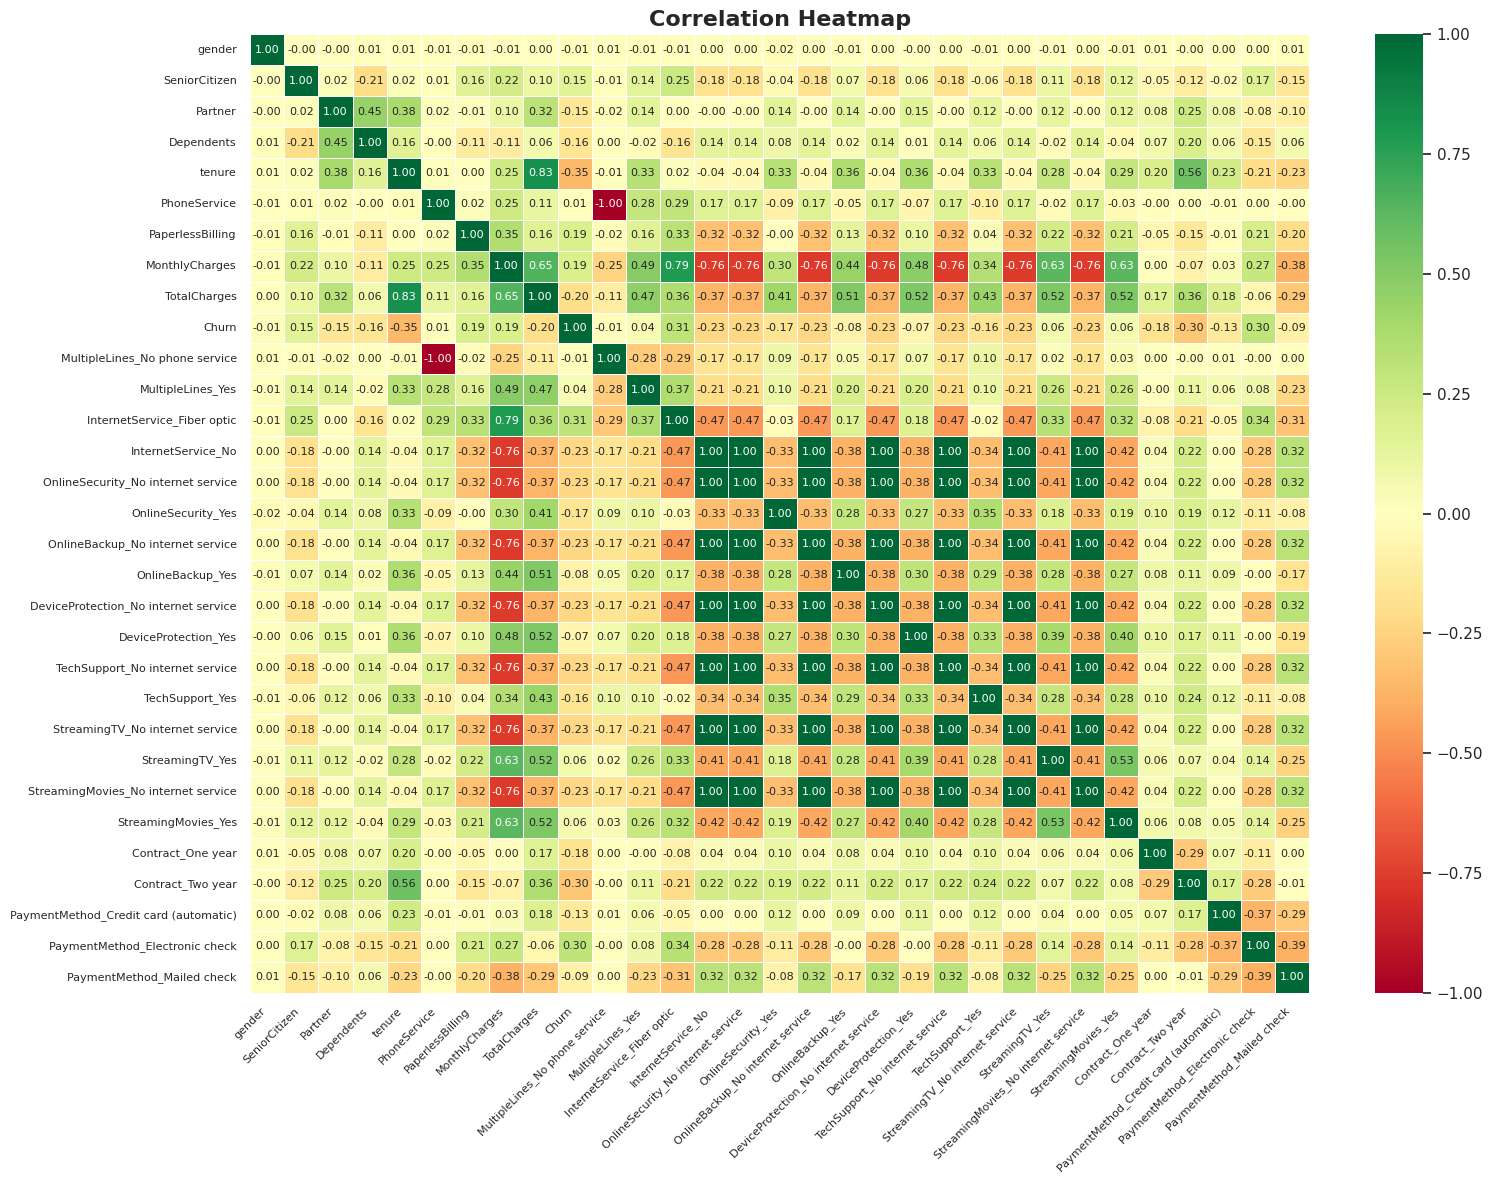

In [117]:
# Properly encode all binary columns
df_corr = df.copy()

# Map all Yes/No and binary columns to 1/0
binary_map = {'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0}
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService',
               'PaperlessBilling', 'Churn']

for col in binary_cols:
    df_corr[col] = df_corr[col].map(binary_map)

# One-hot encode remaining categorical columns
multi_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity',
              'OnlineBackup', 'DeviceProtection', 'TechSupport',
              'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']

df_corr = pd.get_dummies(df_corr, columns=multi_cols, drop_first=True)

# Now all columns are numeric
plt.figure(figsize=(16, 12))
sns.heatmap(df_corr.corr(),
            annot=True,
            fmt='.2f',
            cmap='RdYlGn',
            center=0,
            linewidths=0.5,
            annot_kws={'size': 8})
plt.title('Correlation Heatmap', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

## Correlation Heatmap: Key Relationships

### Churn Correlations (Churn row)
| Feature | Correlation | Interpretation |
|---|---|---|
| Tenure | -0.35 | Strongest predictor — longer customers far less likely to churn |
| Contract_Two year | -0.30 | Two-year contracts are associated with much lower churn |
| TotalCharges | -0.20 | High total = long-term loyal customer |
| MonthlyCharges | +0.19 | Higher bills correlate with churn |
| InternetService_Fiber optic | +0.31 | Fiber optic customers significantly more likely to churn |
| SeniorCitizen | +0.15 | Seniors slightly higher risk |
| PaperlessBilling | +0.19 | Paperless billing customers churn more |
| Gender | -0.01 | No meaningful influence on churn |
| Electronic check| +0.30 |

### New Findings vs Previous Analysis
- **Fiber optic (+0.31)** is actually a stronger churn signal than MonthlyCharges (+0.19), confirms it's not just price but specifically the fiber optic service driving dissatisfaction
- **Two-year contracts (-0.30)** show strong negative correlation, converting customers to long-term contracts is the single most actionable retention lever
- **PaperlessBilling (+0.19)** is a surprise, paperless customers
  churn more, possibly because they are digitally active and more likely
  to compare competitors online

### Key Multicollinearity Notes
- Tenure & TotalCharges: **0.83** - highly correlated, expected (longer customers
  accumulate higher total spend). In modelling, these carry overlapping information
- MonthlyCharges & TotalCharges: **0.65** - moderately correlated
- Multiple "No internet service" columns are perfectly correlated (1.00) with
  each other - these are artifacts of one-hot encoding the same category

### Bottom Line
Tenure, fiber optic, electronic check and contract type show the strongest correlations with churn. Customers who are new, on month-to-month and on fiber optic form the highest-risk segment, but these are associations, not causes.

In [118]:
from sklearn.preprocessing import LabelEncoder

df_model = df.copy()

# Label encode binary columns (Yes/No, Male/Female)
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService',
               'PaperlessBilling', 'Churn']

le = LabelEncoder()
for col in binary_cols:
    df_model[col] = le.fit_transform(df_model[col])

# One-hot encode multi-category columns
multi_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity',
              'OnlineBackup', 'DeviceProtection', 'TechSupport',
              'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']

df_model = pd.get_dummies(df_model, columns=multi_cols, drop_first=True)

print("Shape after encoding:", df_model.shape)
print(df_model.head(2))

Shape after encoding: (7032, 31)
   gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0       0              0        1           0       1             0   
1       1              0        0           0      34             1   

   PaperlessBilling  MonthlyCharges  TotalCharges  Churn  ...  \
0                 1           29.85         29.85      0  ...   
1                 0           56.95       1889.50      0  ...   

   TechSupport_Yes  StreamingTV_No internet service  StreamingTV_Yes  \
0            False                            False            False   
1            False                            False            False   

   StreamingMovies_No internet service  StreamingMovies_Yes  \
0                                False                False   
1                                False                False   

   Contract_One year  Contract_Two year  \
0              False              False   
1               True              False   

   PaymentMethod_Cre

In [119]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict

X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

# Stratified 80/20 split. Scaling happens inside the pipeline below,
# so nothing from the test set leaks into training.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate - train:", y_train.mean().round(3), "| test:", y_test.mean().round(3))

Train: (5625, 30) | Test: (1407, 30)
Churn rate - train: 0.266 | test: 0.266


In [120]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

lr_model = Pipeline([("scale", StandardScaler()),
                     ("lr", LogisticRegression(max_iter=1000, random_state=42))])
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)  # default settings, untuned

lr_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)
rf_preds = rf_model.predict(X_test)

print("=== Logistic Regression ===")
print(classification_report(y_test, lr_preds))
print("ROC-AUC:", roc_auc_score(y_test, lr_model.predict_proba(X_test)[:, 1]).round(3))
print("\n=== Random Forest ===")
print(classification_report(y_test, rf_preds))
print("ROC-AUC:", roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1]).round(3))

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407

ROC-AUC: 0.836

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.50      0.55       374

    accuracy                           0.79      1407
   macro avg       0.72      0.69      0.71      1407
weighted avg       0.77      0.79      0.78      1407

ROC-AUC: 0.815


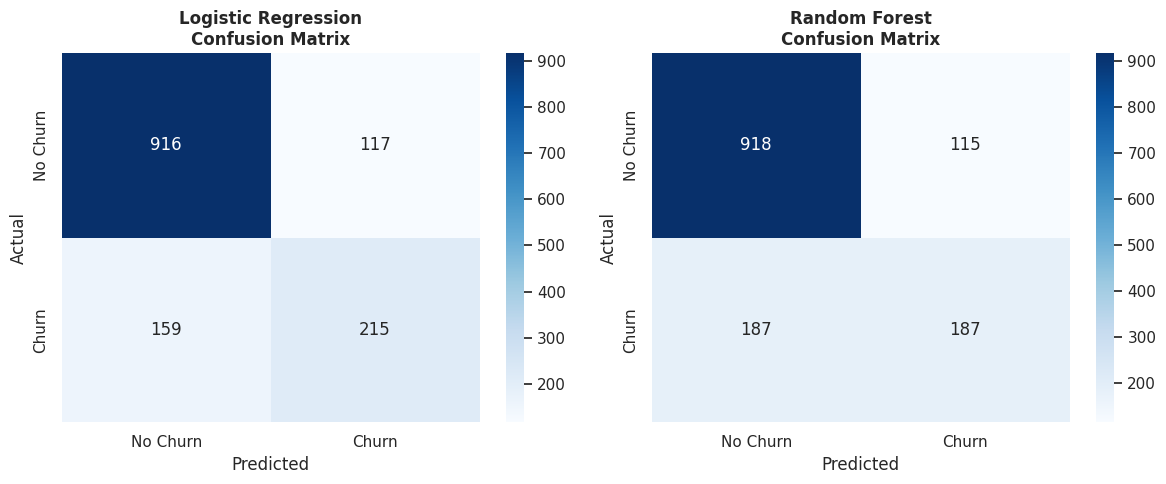

In [121]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, preds, title in zip(axes,
                             [lr_preds, rf_preds],
                             ['Logistic Regression', 'Random Forest']):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No Churn', 'Churn'],
                yticklabels=['No Churn', 'Churn'])
    ax.set_title(f'{title}\nConfusion Matrix', fontweight='bold')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.tight_layout()
plt.show()

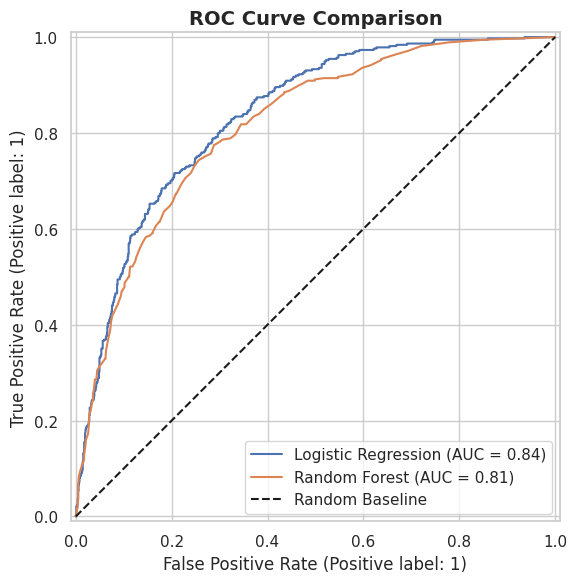

In [122]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(lr_model, X_test, y_test, ax=ax, name='Logistic Regression')
RocCurveDisplay.from_estimator(rf_model, X_test, y_test, ax=ax, name='Random Forest')
ax.plot([0, 1], [0, 1], 'k--', label='Random Baseline')
ax.set_title('ROC Curve Comparison', fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

Threshold analysis on TRAINING data (out-of-fold):
Threshold   Precision   Recall      F1        
0.5         0.653       0.548       0.596     
0.45        0.613       0.603       0.608     
0.4         0.592       0.659       0.624     
0.35        0.564       0.714       0.631     

Held-out TEST set (reported once):
Threshold   Precision   Recall      F1        
0.5         0.648       0.575       0.609     
0.4         0.578       0.684       0.627     


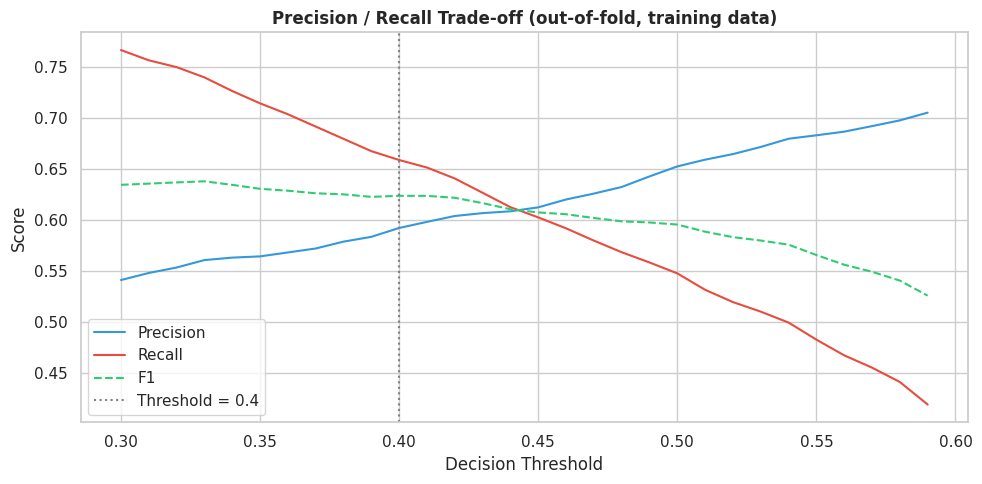

In [123]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

skf = StratifiedKFold(5, shuffle=True, random_state=42)
oof_probs = cross_val_predict(lr_model, X_train, y_train, cv=skf, method="predict_proba")[:, 1]

print("Threshold analysis on TRAINING data (out-of-fold):")
print(f"{'Threshold':<12}{'Precision':<12}{'Recall':<12}{'F1':<10}")
for t in [0.5, 0.45, 0.40, 0.35]:
    pr = (oof_probs >= t).astype(int)
    print(f"{t:<12}{precision_score(y_train, pr):<12.3f}{recall_score(y_train, pr):<12.3f}{f1_score(y_train, pr):<10.3f}")

lr_probs = lr_model.predict_proba(X_test)[:, 1]
print("\nHeld-out TEST set (reported once):")
print(f"{'Threshold':<12}{'Precision':<12}{'Recall':<12}{'F1':<10}")
for t in [0.5, 0.40]:
    pr = (lr_probs >= t).astype(int)
    print(f"{t:<12}{precision_score(y_test, pr):<12.3f}{recall_score(y_test, pr):<12.3f}{f1_score(y_test, pr):<10.3f}")

# Trade-off plot from the training (out-of-fold) predictions
thresh_range = np.arange(0.30, 0.60, 0.01)
precisions = [precision_score(y_train, (oof_probs >= t).astype(int)) for t in thresh_range]
recalls    = [recall_score(y_train, (oof_probs >= t).astype(int)) for t in thresh_range]
f1s        = [f1_score(y_train, (oof_probs >= t).astype(int)) for t in thresh_range]

plt.figure(figsize=(10, 5))
plt.plot(thresh_range, precisions, label='Precision', color='#3498db')
plt.plot(thresh_range, recalls, label='Recall', color='#e74c3c')
plt.plot(thresh_range, f1s, label='F1', color='#2ecc71', linestyle='--')
plt.axvline(x=0.4, color='gray', linestyle=':', label='Threshold = 0.4')
plt.xlabel('Decision Threshold'); plt.ylabel('Score')
plt.title('Precision / Recall Trade-off (out-of-fold, training data)', fontweight='bold')
plt.legend(); plt.tight_layout(); plt.show()

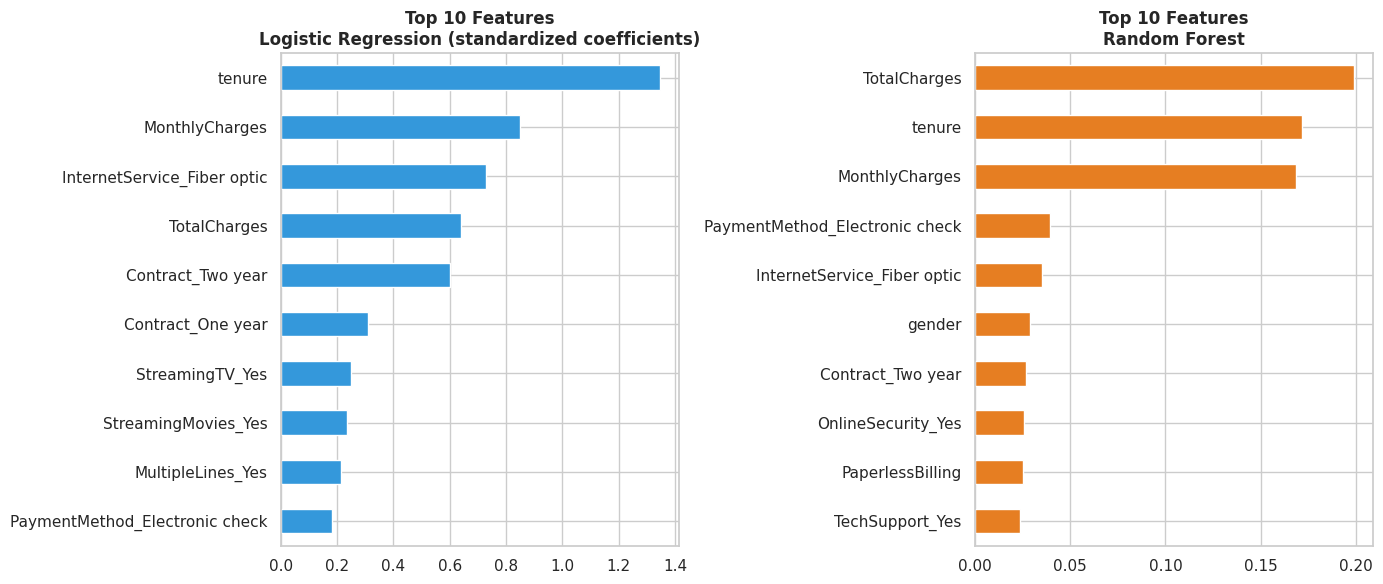

In [124]:
feature_names = X.columns

lr_importance = pd.Series(
    abs(lr_model.named_steps["lr"].coef_[0]), index=feature_names
).sort_values(ascending=False).head(10)

rf_importance = pd.Series(
    rf_model.feature_importances_, index=feature_names
).sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
lr_importance.plot.barh(ax=axes[0], color='#3498db')
axes[0].set_title('Top 10 Features\nLogistic Regression (standardized coefficients)', fontweight='bold')
axes[0].invert_yaxis()
rf_importance.plot.barh(ax=axes[1], color='#e67e22')
axes[1].set_title('Top 10 Features\nRandom Forest', fontweight='bold')
axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

## Model Results

**Setup:** stratified 80/20 split (1,407 test customers). Scaling and cross-validation run inside a pipeline, so nothing from the test set or from held-out folds influences training. The final model uses no resampling.

### Model comparison (held-out test set, default 0.5 threshold)

| Metric | Logistic Regression | Random Forest (default settings) |
|---|---|---|
| Accuracy | 80.4% | 79% |
| Churn precision | 64.8% | 62% |
| Churn recall | 57.5% | 50% |
| ROC-AUC | 0.836 | 0.815 |

Logistic Regression's 5-fold cross-validated ROC-AUC on the training data is 0.846 ± 0.005, consistent with the 0.836 on the test set.

Logistic Regression scored slightly higher than an untuned Random Forest. The gap is small and the Random Forest was not tuned, so this does not show that one algorithm is better in general. It does suggest the churn signal in this dataset is largely additive, which a simple linear model captures well.

### Decision threshold

At the default 0.5 threshold the model misses about 4 in 10 churners. Lowering the threshold to 0.40 trades precision for recall:

| Threshold | Precision | Recall | Accuracy |
|---|---|---|---|
| 0.50 | 64.8% | 57.5% | 80.4% |
| 0.40 | 57.8% | 68.4% (+11 points) | 78.3% |

0.40 was chosen from a small grid (0.50, 0.45, 0.40, 0.35) and then checked on out-of-fold predictions from the training data, not on the test set. There the same pattern holds: recall rises from 54.8% to 65.9% and precision falls from 65.3% to 59.2%. F1 on those folds is fairly flat between 0.30 and 0.45 (about 0.61 to 0.64), so 0.40 is not a sharp optimum. It sits on that plateau and is a recall-focused operating point. Slightly lower thresholds (0.35) score marginally higher on F1 but give up more precision.

The right threshold in practice depends on the cost of missing a churner versus contacting someone who was not going to leave. That cost is not estimated here.

### SMOTE comparison

| Training approach | CV ROC-AUC | Test ROC-AUC | Churn precision / recall at 0.5 |
|---|---|---|---|
| No resampling (final model) | 0.846 ± 0.005 | 0.836 | 0.648 / 0.575 |
| SMOTE inside each CV fold | 0.846 ± 0.005 | 0.834 | 0.497 / 0.781 |

SMOTE did not improve ROC-AUC. It only moved the operating point (more recall, less precision, accuracy down from 80% to 73%), which adjusting the threshold achieves without creating synthetic customers. The simpler no-resampling model was kept.

In [125]:
# SCENARIO, not a measured result. Every assumption is explicit.
subscribers    = 1_000_000
churn_rate     = y.mean()                         # from the data (about 26.6%)
recall         = recall_score(y_test, lr_preds)   # model at 0.5 threshold
precision      = precision_score(y_test, lr_preds)
retention_rate = 0.10    # ASSUMED: share of caught churners successfully retained
monthly_rev    = 70      # ASSUMED $/month (data average for churners is $74.44)
months         = 12      # ASSUMED months of revenue kept

at_risk  = subscribers * churn_rate
caught   = at_risk * recall
flagged  = caught / precision
retained = caught * retention_rate
revenue  = retained * monthly_rev * months

print(f"Churners per year: {at_risk:,.0f}")
print(f"Caught by model: {caught:,.0f} (total flagged incl. false alarms: {flagged:,.0f})")
print(f"Retained at {retention_rate:.0%}: {retained:,.0f}")
print(f"Estimated revenue kept: ${revenue:,.0f}  (ignores offer costs and false-positive costs)")

Churners per year: 265,785
Caught by model: 152,791 (total flagged incl. false alarms: 235,937)
Retained at 10%: 15,279
Estimated revenue kept: $12,834,430  (ignores offer costs and false-positive costs)


## Top Churn Predictors

The charts show how heavily each model uses a feature (absolute standardized coefficient for Logistic Regression, impurity-based importance for Random Forest). They show **magnitude only, not direction or cause**.

### Where the two models agree
- **Tenure** and **MonthlyCharges** are in the top 3 of both models. **TotalCharges** ranks 1st in Random Forest but 4th in Logistic Regression, so the models do not agree on the exact top 3.
- **Fiber optic internet** is in both top 5 (3rd in Logistic Regression, 5th in Random Forest).
- **Two-year contract** appears in both (5th and 7th).

### Where they differ
- Logistic Regression puts weight on contract type (both contract dummies in its top 6). Random Forest ranks **electronic check payment** 4th and also lists online security, paperless billing and tech support in its top 10.

### Direction (from correlations with churn, not from the importance charts)

| Feature | Correlation with churn |
|---|---|
| Tenure | -0.35 |
| Two-year contract | -0.30 |
| Fiber optic | +0.31 |
| Electronic check | +0.30 |
| MonthlyCharges | +0.19 |
| PaperlessBilling | +0.19 |
| TotalCharges | -0.20 |
| OnlineSecurity (Yes) / TechSupport (Yes) | -0.17 / -0.16 |

### Cautions
1. **Overlapping features.** Tenure and TotalCharges correlate at 0.83, and MonthlyCharges and TotalCharges at 0.65, so how credit is split between them is unstable. Read the three as a group rather than ranking them against each other.
2. **Random Forest bias.** Impurity-based importance favours continuous features with many distinct values (tenure, MonthlyCharges, TotalCharges), which partly explains why they dominate. `gender` ranks 6th even though its correlation with churn is about -0.01, which suggests the lower ranks are mostly noise.
3. **Association, not causation.** None of this shows that changing a feature (for example, moving customers to longer contracts) would change churn.

### Bottom line
Tenure is the clearest signal in both models. Billing level, fiber optic service, contract type and electronic-check payment come next. Contract type shows the widest raw churn gap (42.7% vs 2.8%), but tenure has the strongest correlation and the largest Logistic Regression coefficient, so contract type is not the single strongest predictor.

## Business Impact (illustrative scenario, not a measured result)

This section scales the test-set results to a hypothetical operator. The figures below are **model outputs under stated assumptions**, not something the dataset measured.

**From the data / model**
- Churn rate: 26.6% (full dataset)
- Logistic Regression at the default 0.5 threshold: recall 57.5% and precision 64.8% on the held-out test set

**Assumptions (chosen by me, not estimated from the data)**
- 1,000,000 subscribers
- 10% of the churners the model catches are successfully retained
- $70 average monthly revenue per retained customer (the churner average in the data is $74.44)
- Retained customers stay for 12 months

**Scenario results**
- Churners per year: about 265,800
- Caught by the model: about 152,800 (to catch them, the model flags about 235,900 customers, so about 83,000 flags are false alarms)
- Retained at 10%: about 15,300 customers
- Estimated revenue kept: **about $12.8M per year**

**What this ignores**
- **Cost of offers.** The scenario breaks even if the average cost of contacting or incentivising each flagged customer is about $54 per year. Above that it loses money.
- **Revenue vs profit.** The figure is revenue, not margin.
- **The 10% retention rate** is the largest driver and is not estimated here. The result scales linearly: 5% retention gives about $6.4M, 20% gives about $25.7M.


In [126]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

candidates = {
    "No SMOTE (final model)": lr_model,
    "SMOTE inside each fold": ImbPipeline([
        ("scale", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("lr", LogisticRegression(max_iter=1000, random_state=42))]),
}

for name, pipe in candidates.items():
    cv = cross_val_score(pipe, X_train, y_train, cv=skf, scoring="roc_auc")
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    print(f"{name}: CV AUC {cv.mean():.3f} ± {cv.std():.3f} | test AUC {roc_auc_score(y_test, p):.3f}")
    for t in (0.5, 0.4):
        pr = (p >= t).astype(int)
        print(f"  threshold {t}: precision {precision_score(y_test, pr):.3f} | recall {recall_score(y_test, pr):.3f}")

No SMOTE (final model): CV AUC 0.846 ± 0.005 | test AUC 0.836
  threshold 0.5: precision 0.648 | recall 0.575
  threshold 0.4: precision 0.578 | recall 0.684
SMOTE inside each fold: CV AUC 0.846 ± 0.005 | test AUC 0.834
  threshold 0.5: precision 0.497 | recall 0.781
  threshold 0.4: precision 0.459 | recall 0.861


In [127]:
df_corr.corr()['Churn'].sort_values()

,Churn
tenure,-0.354049
Contract_Two year,-0.301552
InternetService_No,-0.227578
OnlineSecurity_No internet service,-0.227578
DeviceProtection_No internet service,-0.227578
StreamingTV_No internet service,-0.227578
OnlineBackup_No internet service,-0.227578
StreamingMovies_No internet service,-0.227578
TechSupport_No internet service,-0.227578
TotalCharges,-0.199484


In [128]:
churned = df[df['Churn'] == 'Yes']
print("Share of churners with tenure <= 6 months: ", round((churned['tenure'] <= 6).mean(), 3))
print("Share of churners with tenure <= 12 months:", round((churned['tenure'] <= 12).mean(), 3))

df['tenure_bucket'] = pd.cut(df['tenure'], [0, 6, 12, 24, 48, 72], include_lowest=True)
print(df.groupby('tenure_bucket', observed=True)['Churn'].apply(lambda s: (s == 'Yes').mean()).round(3))

Share of churners with tenure <= 6 months:  0.419
Share of churners with tenure <= 12 months: 0.555
tenure_bucket
(-0.001, 6.0]    0.533
(6.0, 12.0]      0.359
(12.0, 24.0]     0.287
(24.0, 48.0]     0.204
(48.0, 72.0]     0.095
Name: Churn, dtype: float64
